# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**О выполнении.** Выполнены разделы 1–6, ветка 5.2 с targeted-атакой и все бонусы 7.1–7.5. Ветка 5.3 не выбрана. Блокнот целиком запущен в новом ядре с `FAST_MODE=False`

Использованы NVIDIA GeForce RTX 3050 Laptop GPU, PyTorch 2.11.0+cu128 и 4 потока CPU


In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu128
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = device.type == 'cuda'
torch.backends.cudnn.deterministic = True
set_seed(0)
device

device(type='cuda')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [6]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    # собираем участки
    cols = F.unfold(x, kernel_size=(kh, kw), dilation=dilation,
                    padding=padding, stride=stride)
    L = cols.shape[-1]

    # выделяем группы и разворачиваем веса
    patch_size = (C_in // groups) * kh * kw
    cols = cols.reshape(B, groups, patch_size, L)
    weight_flat = weight.reshape(groups, C_out // groups, patch_size)

    out = weight_flat @ cols

    # объединяем группы и восстанавливаем оси
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    out = out.reshape(B, C_out, H_out, W_out)

    if bias is not None:
        out = out + bias.reshape(1, C_out, 1, 1)
    return out

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** `cols` занимает в 9, 25 и 49 раз больше памяти, чем вход, для ядер 3 на 3, 5 на 5 и 7 на 7 при одинаковом dtype. При stride=1 и padding=k//2 число позиций сохраняется. Для каждой позиции unfold записывает по k^2 значений на канал, отсюда и множитель k^2. Большое ядро требует больше памяти для im2col и больше вычислений. Поэтому для крупных ядер может быть выгодна FFT-свёртка, а для маленьких затраты на FFT часто не окупаются.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        H, W = x.shape[-2:]
        kh, kw = weight.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]

        op_h = H - ((H_out - 1) * s - 2 * p + kh)
        op_w = W - ((W_out - 1) * s - 2 * p + kw)
        grad_x = F.conv_transpose2d(
            grad_out, weight, stride=s, padding=p,
            output_padding=(op_h, op_w),
        )

        cols = F.unfold(x, kernel_size=(kh, kw), stride=s, padding=p)
        grad_flat = grad_out.flatten(2)
        grad_w_per_image = grad_flat @ cols.transpose(1, 2)
        grad_w = grad_w_per_image.sum(dim=0).reshape_as(weight)

        # одно смещение используется во всех позициях своего канала
        grad_b = grad_out.sum(dim=(0, 2, 3)) if ctx.needs_input_grad[2] else None
        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** При высоте входа 7 или 8 свёртка с ядром 3 на 3, stride=2 и padding=1 даёт одинаковую высоту выхода 4. Обратная формула даёт (4−1)*2−2+3+output_padding = 7+output_padding. Поэтому для восстановления высоты 7 нужен output_padding=0, а для высоты 8 нужен output_padding=1. По одной форме выхода нельзя определить, какой из двух входов был исходным.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [12]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    out = model(x)
    h, w = out.shape[-2:]
    center = out[0, :, h // 2, w // 2].sum()
    grad_x, = torch.autograd.grad(center, x)

    # пиксель учитываем, если градиент != 0 хотя бы в одном канале
    mask = (grad_x[0] != 0).any(dim=0)
    rows, cols = torch.where(mask)
    if rows.numel() == 0:
        return (0, 0)

    height = (rows.max() - rows.min() + 1).item()
    width = (cols.max() - cols.min() + 1).item()
    return (height, width)

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** У усредняющих ядер все веса положительные, а нелинейности не обрывают пути градиента. Поэтому ненулевой градиент покрывает все достижимые пиксели, и его bounding box совпадает с теоретическим рецептивным полем. У MaxPool градиент проходит только через выбранные максимумы. Он становится разреженным и зависит от входа, но bounding box при этом может остаться прежним. В проверке conv-pool он равен 18 на 18 для обоих вариантов.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [14]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    if n_inputs < 1:
        raise ValueError('n_inputs must be positive')
    grad_map = torch.zeros(size, size)
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)
        out = model(x)
        h, w = out.shape[-2:]
        center = out[0, :, h // 2, w // 2].sum()
        grad_x, = torch.autograd.grad(center, x)
        grad_map += grad_x[0].abs().sum(dim=0)
    grad_map /= n_inputs

    row_mass = grad_map.sum(dim=1)
    total = row_mass.sum()
    if total.item() == 0:
        raise ValueError('Cannot normalize all zero gradient map')
    probabilities = row_mass / total

    positions = torch.arange(size, dtype=probabilities.dtype)
    mean = (positions * probabilities).sum()
    variance = ((positions - mean).square() * probabilities).sum()
    return variance.sqrt().item()

In [15]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [16]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


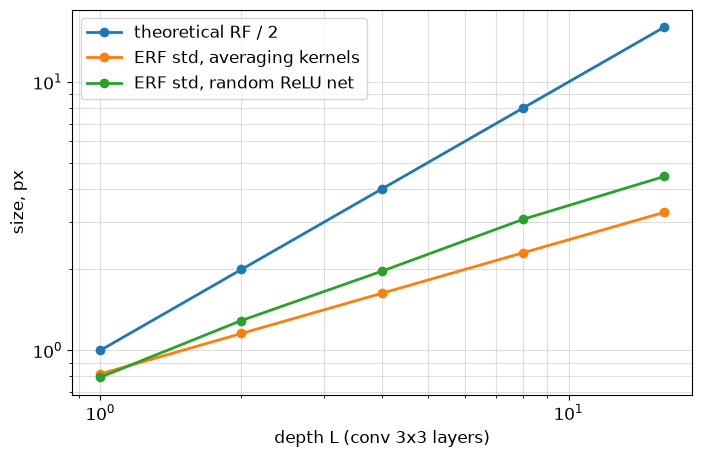

In [17]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** У усредняющей сети std растёт как sqrt(2L/3), а теоретическая полуширина рецептивного поля равна L. Поэтому на log-log графике наклоны равны 0.5 и 1, а отношение std к размеру поля уменьшается как 1/sqrt(L). При увеличении глубины с 1 до 16 std вырос с 0.82 до 3.27 пикселя у усредняющей сети и с 0.79 до 4.44 у случайной ReLU-сети. В обоих случаях эффективная ширина растёт медленнее теоретического поля. Разницу между сетями нельзя объяснить только ReLU, ведь у них также разные веса и число каналов.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [18]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if x.ndim != 4:
            raise ValueError('Expected a 4D tensor (B, C, H, W)')
        if x.shape[1] != self.weight.numel():
            raise ValueError('Input channel count does not match num_features')

        if self.training:
            n = x.shape[0] * x.shape[2] * x.shape[3]
            if n <= 1:
                raise ValueError('Expected more than one value per channel in training')
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), unbiased=False)
            with torch.no_grad():
                self.num_batches_tracked.add_(1)
                m = self.momentum
                if m is None:
                    m = 1.0 / self.num_batches_tracked.item()
                self.running_mean.lerp_(mean, m)
                # поправка Бесселя
                self.running_var.lerp_(var * (n / (n - 1)), m)
        else:
            mean, var = self.running_mean, self.running_var

        shape = (1, -1, 1, 1)
        normalized = (x - mean.view(shape)) * torch.rsqrt(var.view(shape) + self.eps)
        return normalized * self.weight.view(shape) + self.bias.view(shape)

In [19]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** Для текущего батча BatchNorm делит сумму квадратов отклонений на n. Это даёт единичную эмпирическую дисперсию нормализованных значений, если не учитывать eps. Для running variance нужна оценка дисперсии распределения, поэтому используется поправка Бесселя n/(n−1). При независимых наблюдениях она убирает смещение оценки. Для B=4 и карты 5 x 5 получаем n=100 и разницу около 1.01%. Для B=2 и карты 1 x 1 получаем n=2, и оценки различаются вдвое.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** Для выходного канала $o$ положим $a_o=\gamma_o/\sqrt{\hat\sigma_o^2+\varepsilon}$. Тогда $\mathrm{BN}(W_o*x+b_o)=a_o(W_o*x+b_o-\hat\mu_o)+\beta_o$. Значит, можно взять $W\prime_o=a_oW_o$ и $b\prime_o=a_o(b_o-\hat\mu_o)+\beta_o$. Если bias не было, подставляем $b_o=0$. Множитель применяется ко всем весам соответствующего выходного фильтра. Это работает и для groups.

In [20]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    if conv.training or bn.training:
        raise ValueError('Fusion requires eval mode')
    if not bn.affine or not bn.track_running_stats:
        raise ValueError('BatchNorm must have affine parameters and running statistics')

    # deepcopy сохраняет все что нужно
    fused = copy.deepcopy(conv)
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    fused.bias = nn.Parameter((bias - bn.running_mean) * scale + bn.bias)
    return fused


def fuse_sequential(seq):
    if seq.training:
        raise ValueError('Fusion requires eval mode')
    modules = list(seq)
    fused_modules = []
    i = 0
    while i < len(modules):
        if (i + 1 < len(modules) and isinstance(modules[i], nn.Conv2d)
                and isinstance(modules[i + 1], nn.BatchNorm2d)):
            fused_modules.append(fuse_conv_bn(modules[i], modules[i + 1]))
            i += 2
        else:
            fused_modules.append(copy.deepcopy(modules[i]))
            i += 1
    return nn.Sequential(*fused_modules).eval()

In [21]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [22]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим, копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [23]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 60.2 ms   fused: 59.1 ms   speedup 1.02x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В eval BatchNorm использует фиксированные среднее и дисперсию, поэтому его преобразование можно включить в веса и bias свёртки. В train статистики зависят от батча, и одна фиксированная свёртка их не заменит. Слияние убирает отдельную операцию BN и запись промежуточного тензора. Время Conv + BN составило 60.2 мс, после слияния 59.1 мс. Отношение времён равно 1.02. Слияние немного ускорило вычисление в этом замере. Это минимум из пяти повторов на CPU, результат зависит от размеров и используемой реализации.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Для симметричного распределения $\mathbb E[\mathrm{ReLU}(h)^2]=\frac12\mathbb E[h^2]$. Если среднее предактиваций равно нулю, получаем $\mathrm{Var}(h_l)=nv\,\mathrm{Var}(h_{l-1})/2$. Чтобы масштаб не менялся, нужна дисперсия весов $v=2/n$, как в Kaiming. Для tanh около нуля функция почти линейна, поэтому подходит $v=1/n$, как в Xavier при одинаковой ширине слоёв. У стандартной инициализации Linear дисперсия весов равна $1/(3n)$. Для ReLU это даёт уменьшение дисперсии примерно в 6 раз за слой, а std в sqrt(6) раз. Для std после ReLU это приближение предполагает, что форма распределения сохраняется.

In [24]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    history = []
    with torch.no_grad():
        for _ in range(depth):
            layer = nn.Linear(width, width, bias=False)
            init(layer.weight)
            h = act(layer(h))
            history.append(h.std().item())
    return history

In [25]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.41000275082847326)

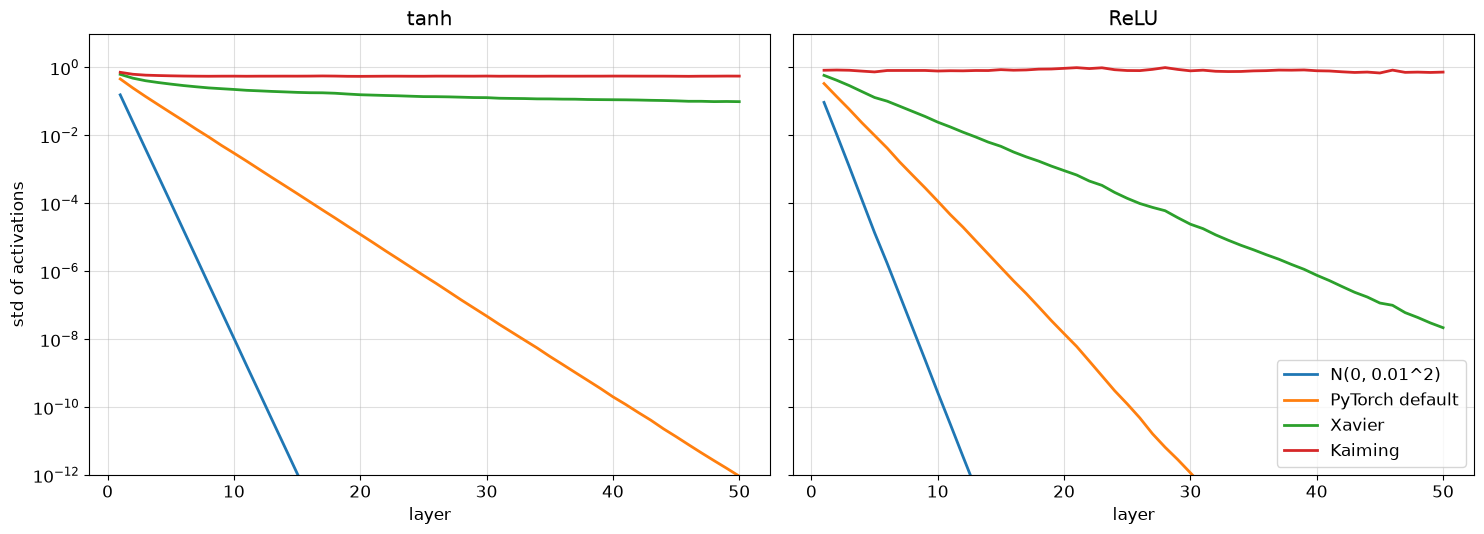

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Kaiming + ReLU лучше сохраняет масштаб на большой глубине. Std первого слоя равен 0.830, последнего 0.732, отношение 0.882. Для Xavier + tanh std меняется с 0.628 до 0.099. Tanh сжимает значения, поэтому даже подходящая инициализация не гарантирует сохранения масштаба на любой глубине. У Kaiming + tanh std меняется с 0.721 до 0.558, но это само по себе не говорит о сохранении градиентов. Для default + ReLU множитель std за слой равен 0.410, близко к 1/sqrt(6). В ResNet дополнительно работают BatchNorm и residual-связи, поэтому результат этого опыта с обычным MLP нельзя напрямую переносить на ResNet.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [27]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError('MyAdamW does not support sparse gradients')
                state = self.state[p]
                if not state:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                state['step'] += 1
                t = state['step']
                m, v = state['exp_avg'], state['exp_avg_sq']

                # отдельное изменение
                p.mul_(1 - group['lr'] * group['weight_decay'])
                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                if group['bias_correction']:
                    correction1 = 1 - beta1 ** t
                    correction2 = 1 - beta2 ** t
                else:
                    correction1 = correction2 = 1.0
                denominator = (v / correction2).sqrt().add_(group['eps'])
                p.addcdiv_(m, denominator, value=-group['lr'] / correction1)

In [28]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [29]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


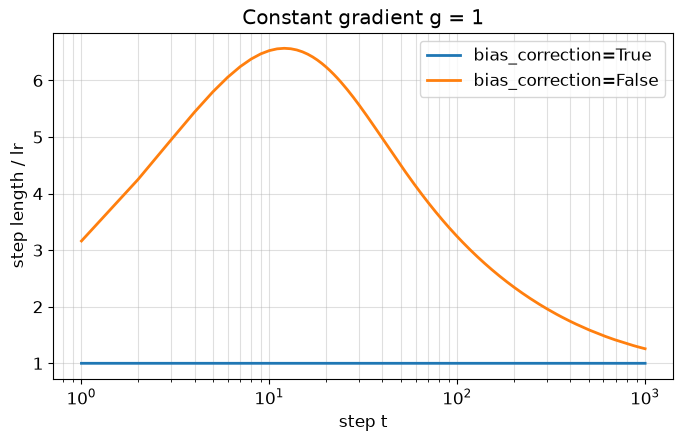

In [30]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** При постоянном градиенте $g_t=1$ получаем $m_t=1-\beta_1^t$ и $v_t=1-\beta_2^t$. Без bias correction и weight decay длина шага равна $\eta(1-\beta_1^t)/(\sqrt{1-\beta_2^t}+\epsilon)$. В опыте отношение шага к lr на шагах 1, 10, 100 и 1000 равно 3.16, 6.53, 3.24, 1.26. Максимум 6.57 получился на шаге 12. Из-за разной скорости накопления моментов начальные шаги оказываются намного больше lr. Это может мешать устойчивому обучению. С bias correction отношение в этом опыте остаётся около 1.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [31]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    if total_steps <= 0:
        raise ValueError('total_steps must be positive')
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [32]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

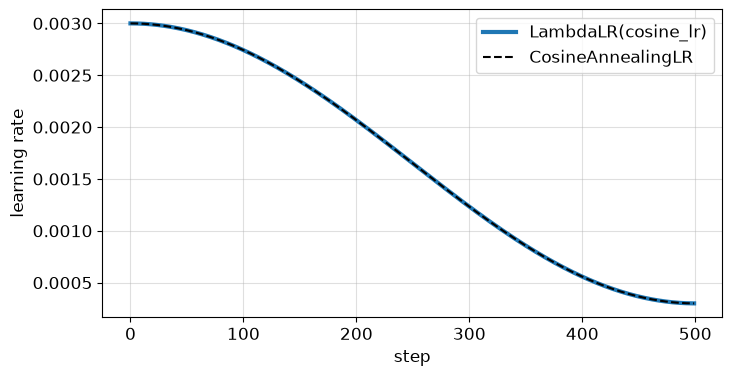

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность AdamW меняет масштаб отдельных координат, но общий learning rate всё равно задаёт размер обновления. Его уменьшение ослабляет влияние шума мини-батчей и помогает точнее подойти к минимуму. При постоянном шаге параметры могут продолжать колебаться около него, даже если оптимизатор адаптивный.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [34]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

C:\Users\tsernitsyne\Desktop\codes\python_code\hw1_students\.venv-gpu\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

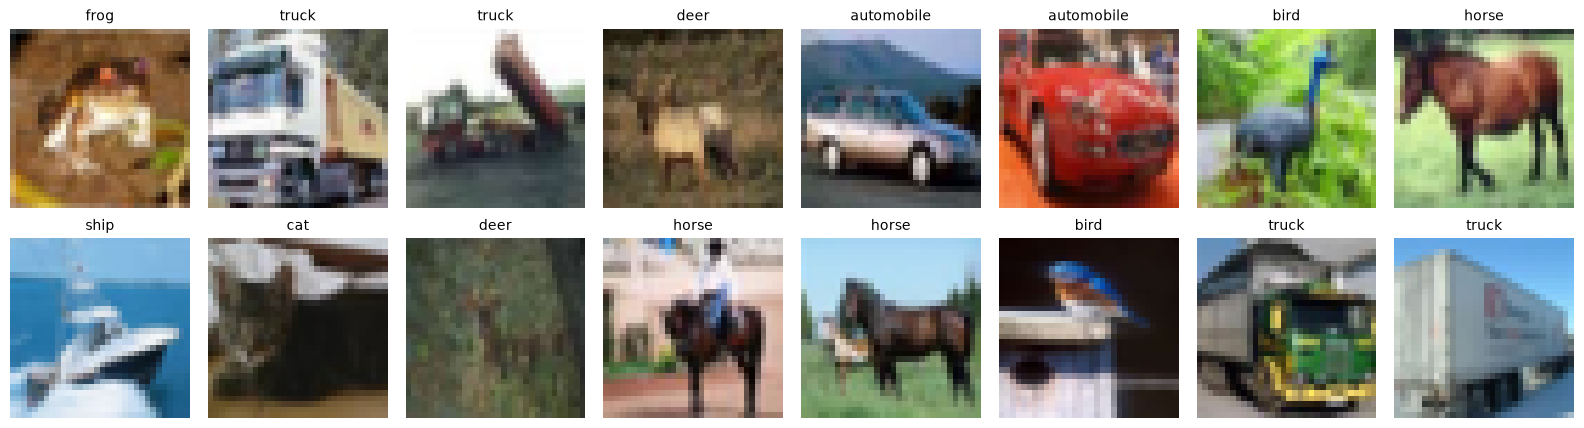

In [35]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [36]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )
    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, separable=separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            self.shortcut = (
                nn.Identity() if stride == 1 and c_in == c_out else nn.Sequential(
                    nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                    nn.BatchNorm2d(c_out),
                )
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        assert n >= 1 and len(widths) == 3
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]), nn.ReLU(),
        )
        stages, c_in = [], widths[0]
        for stage_index, c_out in enumerate(widths):
            blocks = []
            for block_index in range(n):
                stride = 2 if stage_index > 0 and block_index == 0 else 1
                blocks.append(Block(c_in, c_out, stride, residual, separable))
                c_in = c_out
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        out = self.stages(self.stem(x))
        return self.fc(self.pool(out).flatten(1))

In [37]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [38]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    groups = [
        dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=weight_decay),
        dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0),
    ]
    optimizer = MyAdamW(groups, lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: cosine_lr(step, total_steps, min_ratio=0.0))
    history = dict(train_loss=[], test_acc=[])
    started = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        for x_batch, y_batch in iterate_batches(
                X_train, Y_train, batch_size, transform=normalize):
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x_batch), y_batch)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item() * len(y_batch)
        history['train_loss'].append(loss_sum / len(X_train))
        logits_test = predict_logits(model, X_test, batch_size=batch_size, transform=normalize)
        history['test_acc'].append(accuracy(logits_test, Y_test))
        if log:
            print(f'Epoch {epoch+1:2}/{epochs}: loss={history["train_loss"][-1]:.4f}, '
                  f'test_acc={history["test_acc"][-1]:.4f}, '
                  f'lr={scheduler.get_last_lr()[0]:.6f}, '
                  f'minutes={(time.perf_counter()-started)/60:.1f}', flush=True)
    model._training_elapsed_seconds = time.perf_counter() - started
    return history


In [39]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = resnet20._training_elapsed_seconds
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}


Epoch  1/20: loss=1.4572, test_acc=0.4635, lr=0.002982, minutes=0.4


Epoch  2/20: loss=0.9930, test_acc=0.6294, lr=0.002927, minutes=0.6


Epoch  3/20: loss=0.8035, test_acc=0.6493, lr=0.002837, minutes=0.7


Epoch  4/20: loss=0.6675, test_acc=0.7435, lr=0.002714, minutes=0.9


Epoch  5/20: loss=0.5806, test_acc=0.7183, lr=0.002561, minutes=1.1


...

Epoch 17/20: loss=0.0215, test_acc=0.8283, lr=0.000163, minutes=3.1


Epoch 18/20: loss=0.0173, test_acc=0.8307, lr=0.000073, minutes=3.3


Epoch 19/20: loss=0.0147, test_acc=0.8307, lr=0.000018, minutes=3.5


Epoch 20/20: loss=0.0140, test_acc=0.8296, lr=0.000000, minutes=3.7


{'train acc': 0.9993999600410461, 'test acc': 0.8295999765396118}

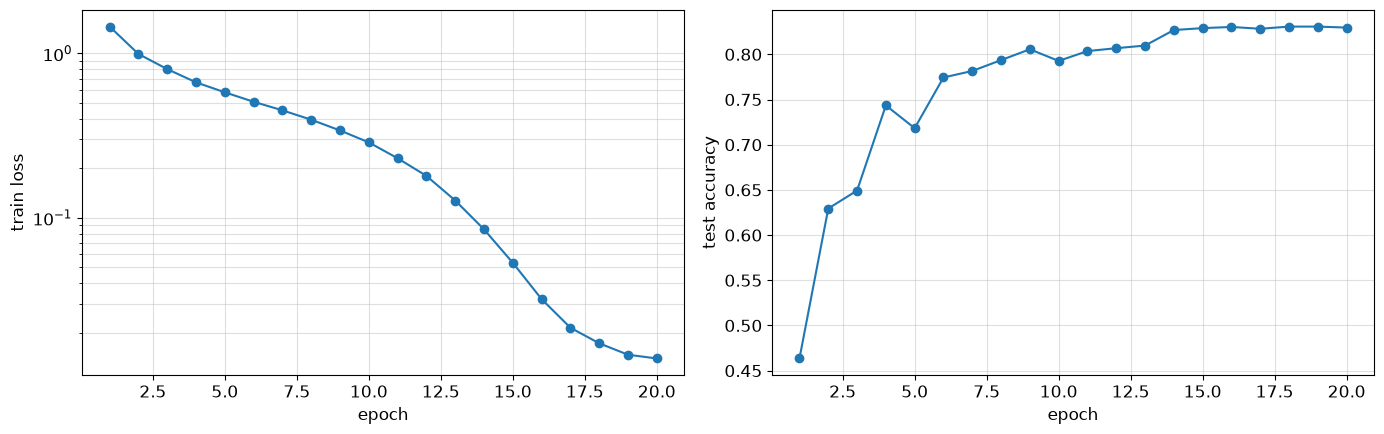

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()


**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** После 20 эпох train accuracy на первых 10 000 train изображениях составила 99.94%, test accuracy на всех 10 000 test изображениях составила 82.96%. Разрыв равен 16.98 процентного пункта. На последних трёх эпохах train loss равен 0.0173, 0.0147, 0.0140, а test accuracy равна 83.07%, 83.07%, 82.96%. К концу обучения loss снижается при уменьшении lr, но test accuracy не обязана расти на каждом шаге. Модель намного лучше распознаёт обучающие данные, что показывает ограничение её обобщения.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [41]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [42]:
ablation = {}
for name, config in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**config)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    seconds = model._training_elapsed_seconds
    ablation[name] = dict(
        params=n_params(model),
        train_acc=accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000]),
        test_acc=hist['test_acc'][-1],
        minutes=seconds / 60,
        history=hist,
    )
    RUN_TIMES[f'cifar_{name}_seconds'] = seconds

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')


Epoch  1/10: loss=1.6958, test_acc=0.3282, lr=0.002927, minutes=0.2


Epoch  2/10: loss=1.3330, test_acc=0.4519, lr=0.002714, minutes=0.3


Epoch  3/10: loss=1.1098, test_acc=0.5912, lr=0.002382, minutes=0.5


Epoch  4/10: loss=0.9426, test_acc=0.6401, lr=0.001964, minutes=0.6


Epoch  5/10: loss=0.8112, test_acc=0.6880, lr=0.001500, minutes=0.8


...

Epoch  7/10: loss=1.2819, test_acc=0.5202, lr=0.000618, minutes=3.2


Epoch  8/10: loss=1.1887, test_acc=0.5665, lr=0.000286, minutes=3.7


Epoch  9/10: loss=1.1220, test_acc=0.5831, lr=0.000073, minutes=4.2


Epoch 10/10: loss=1.0785, test_acc=0.5921, lr=0.000000, minutes=4.6


model                    params  train acc  test acc  minutes
plain-20                269,722     0.8516    0.7840      1.5
plain-56                853,018     0.6178    0.5921      4.6


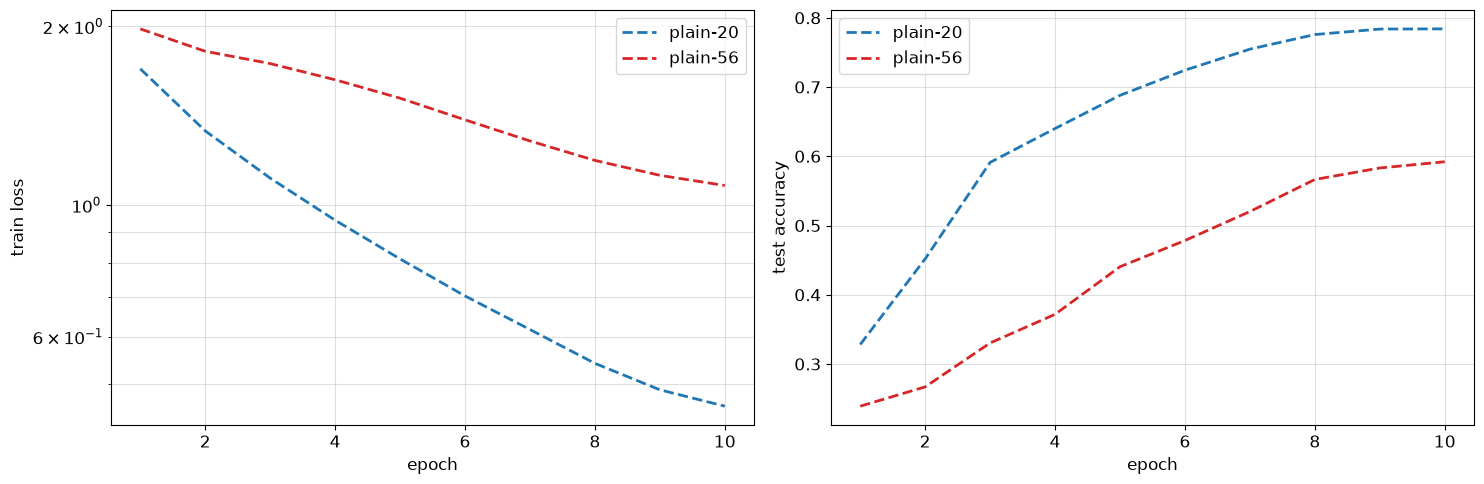

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** За одинаковые 10 эпох plain-20 получила train loss 0.4583, а plain-56 получила 1.0785. Train accuracy равна 85.16% и 61.78%, test accuracy равна 78.40% и 59.21%. У глубокой сети хуже уже результат на train. Это указывает на трудности оптимизации при данном бюджете, а одним переобучением такое ухудшение не объяснить. Для проверки роли shortcut стоит сравнить plain-56 и ResNet-56 при одинаковых seed, lr и числе эпох. Основная ResNet-20 обучалась дольше, поэтому её результат не даёт такого контроля.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [45]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

datasets.FashionMNIST.mirrors = ['https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/']
fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [46]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))



def _fashion_fit(model, epochs, lr, attack=None, eps=None, log=True):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = dict(train_loss=[], clean=[], fgsm=[], pgd=[])
    name = 'standard' if attack is None else f'{attack.__name__}-eps-{eps}'
    started = time.perf_counter()
    for epoch in range(epochs):
        loss_sum = 0.0
        for x, y in iterate_batches(XF_train, YF_train, 128):
            optimizer.zero_grad(set_to_none=True)
            if attack is not None:
                model.eval()
                x = attack(model, x, y, eps).detach()
            model.train()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
        model.eval()
        optimizer.zero_grad(set_to_none=True)
        history['train_loss'].append(loss_sum / len(XF_train))
        x_eval, y_eval = XF_test[:1000], YF_test[:1000]
        history['clean'].append(attack_accuracy(model, x_eval, y_eval, batch_size=128))
        if attack is not None:
            history['fgsm'].append(attack_accuracy(model, x_eval, y_eval, fgsm_attack,
                                                  batch_size=128, eps=eps))
            history['pgd'].append(attack_accuracy(model, x_eval, y_eval, pgd,
                                                 batch_size=128, eps=eps))
        if log:
            extra = (f', FGSM={history["fgsm"][-1]:.3f}, PGD-20={history["pgd"][-1]:.3f}'
                     if attack is not None else '')
            print(f'Fashion {name}, epoch {epoch+1}/{epochs}: '
                  f'loss={history["train_loss"][-1]:.4f}, clean={history["clean"][-1]:.3f}'
                  f'{extra}, minutes={(time.perf_counter()-started)/60:.1f}', flush=True)
    model.eval()
    model.zero_grad(set_to_none=True)
    model._training_history = history
    model._training_elapsed_seconds = time.perf_counter() - started
    return history


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    _fashion_fit(model, epochs, lr)
    return model


In [47]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [48]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = model_a._training_elapsed_seconds
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

Fashion standard, epoch 1/5: loss=0.5202, clean=0.866, minutes=0.1


Fashion standard, epoch 2/5: loss=0.3263, clean=0.878, minutes=0.1


Fashion standard, epoch 3/5: loss=0.2919, clean=0.908, minutes=0.1


Fashion standard, epoch 4/5: loss=0.2672, clean=0.909, minutes=0.2


Fashion standard, epoch 5/5: loss=0.2436, clean=0.907, minutes=0.2


{'clean': 0.907, 'FGSM, eps=0.1': 0.068, 'PGD-20, eps=0.1': 0.002}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [49]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()
    model.eval()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        # отдельная норма для каждой картинки, не одна на весь батч
        norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12)
        shape = (-1,) + (1,)*(x.ndim-1)
        proposal = x_adv.detach() + alpha*grad/norm.view(shape)
        delta = proposal-x
        delta_norm = delta.flatten(1).norm(dim=1).clamp_min(1e-12)
        scale = (eps/delta_norm).clamp(max=1).view(shape)
        x_adv = (x + delta*scale).clamp(0, 1).detach()
    return x_adv.detach()

In [50]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.910; маленькое падение требует диагностики.


(0.91, 0.0)

In [51]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.907,
  0.5: 0.431,
  1.0: 0.086,
  1.5: 0.006,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.002)

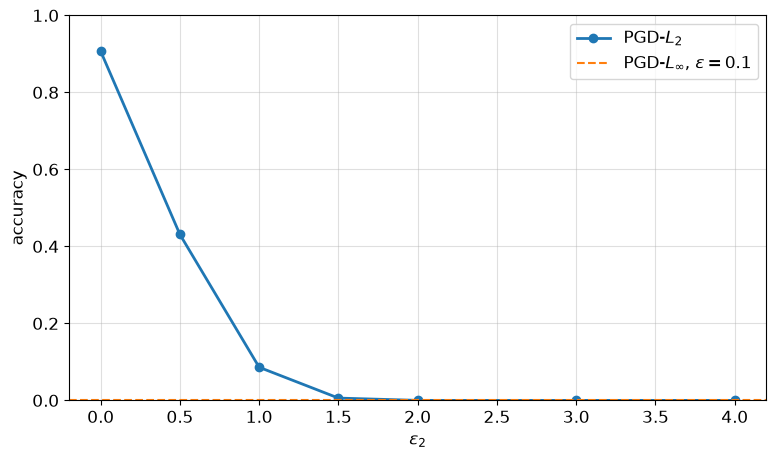

In [52]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=2.0, accuracy gap=0.002


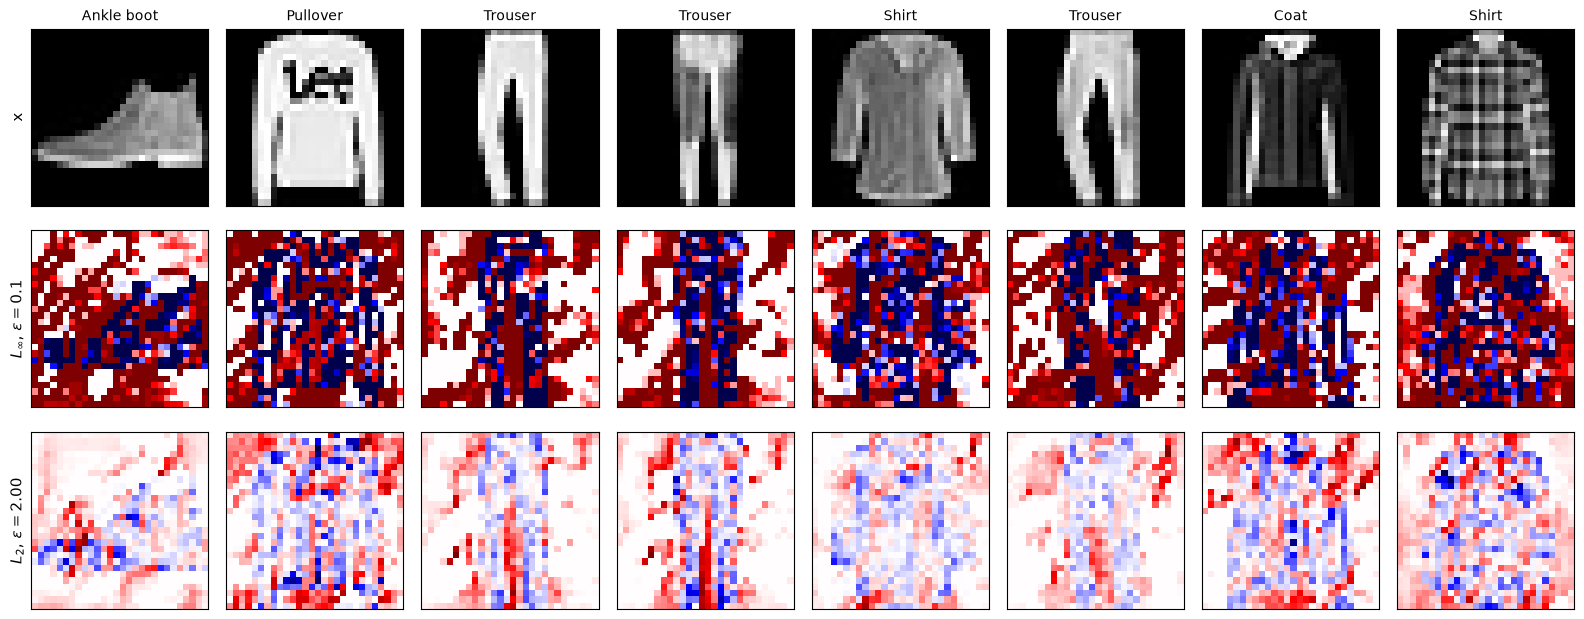

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.134
$L_2$, $\varepsilon=2.00$    L_inf = 0.393   L_2 = 1.988


In [53]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближайшая точка сетки получилась при eps_2=2.0. Accuracy равна 0.000 против 0.002 для L_inf с eps=0.1. Разрыв равен 0.002, поэтому это только приближённое совпадение на выбранной сетке. Средняя L_2-норма L_inf-возмущения на восьми примерах равна 2.134. На картинках L_2-возмущение заметнее выделяет отдельные детали и края, хотя меняет и фон. Цветовые шкалы нормированы отдельно. L_2-шаг учитывает величины компонент градиента и сильнее тратит бюджет на важные пиксели. L_inf-шаг использует только знак градиента.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [54]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        model.eval()
        x = x.detach()
        target = torch.as_tensor(target, dtype=torch.long, device=x.device)
        if target.ndim == 0:
            target = target.expand(len(x))
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1).detach()
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha*grad.sign()
            x_adv = torch.maximum(torch.minimum(x_adv, x+eps), x-eps).clamp(0, 1).detach()
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        result = torch.full((n_classes, n_classes), float('nan'))
        counts = torch.bincount(y.detach().cpu(), minlength=n_classes).float()
        present = counts > 0
        for target in range(n_classes):
            hits = torch.zeros(n_classes)
            eligible = torch.where(y != target)[0]
            for start in range(0, len(eligible), 128):
                idx = eligible[start:start+128]
                targets = torch.full_like(y[idx], target)
                adv = pgd_targeted(model, x[idx], targets, eps,
                                   alpha=2.5*eps/max(steps, 1), steps=steps)
                with torch.no_grad():
                    success = (model(adv).argmax(1) == target).float().cpu()
                hits.scatter_add_(0, y[idx].cpu(), success)
            result[present, target] = hits[present]/counts[present]
        result.fill_diagonal_(float('nan'))
        return result

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.720; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.87 0.   0.02 0.03 0.   0.   0.08 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.03 0.   0.82 0.01 0.05 0.   0.09 0.   0.   0.  ]
 [0.05 0.   0.01 0.89 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.   0.04 0.05 0.81 0.   0.1  0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.06 0.   0.02 0.04 0.04 0.   0.84 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.98 0.01 0.  ]
 [0.01 0.   0.   0.   0.   0.01 0.   0.   0.98 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.03 0.   0.96]]


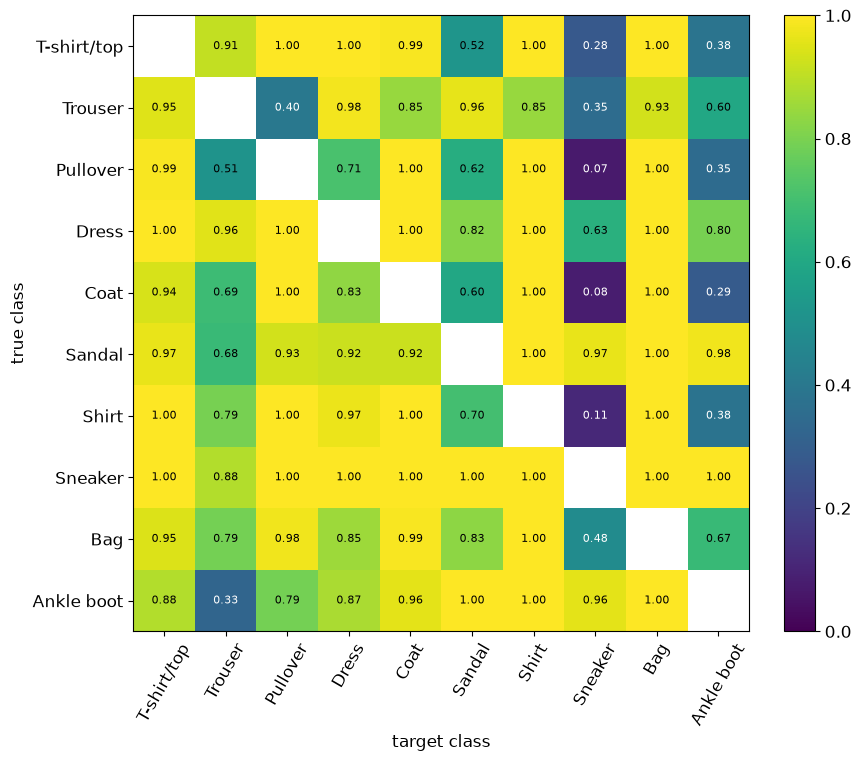

In [56]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Самые лёгкие направления в этом опыте: Ankle boot - Bag (1.00), Ankle boot - Shirt (1.00), Ankle boot - Sandal (1.00). Среди самых трудных: Pullover - Sneaker (0.07), Coat - Sneaker (0.08), Shirt - Sneaker (0.11). При совпадающих значениях это примеры, а не уникальный рейтинг. Матрица несимметрична: для Pullover - Sneaker доля успеха равна 0.07, а в обратную сторону 1.00. Самая частая clean-ошибка: Coat - Shirt (0.10). Targeted success для этой пары равен 1.00. Для Ankle boot - Bag clean-путаница равна нулю, но targeted success равен 1.00. Значит, отсутствие clean-ошибок между классами не мешает атаке переводить один в другой. Матрица учитывает все изображения исходного класса, в том числе clean-ошибки. На класс приходится примерно сотня объектов, поэтому небольшую разницу долей не стоит переоценивать.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [57]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [58]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [59]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    history = _fashion_fit(model, epochs, lr, attack=attack, eps=eps, log=log)
    return {key: history[key] for key in ['clean', 'fgsm', 'pgd']}

In [60]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = robust[name]._training_elapsed_seconds
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7


Fashion pgd7_attack-eps-0.1, epoch 1/5: loss=1.0179, clean=0.807, FGSM=0.687, PGD-20=0.641, minutes=0.2


Fashion pgd7_attack-eps-0.1, epoch 2/5: loss=0.8203, clean=0.819, FGSM=0.708, PGD-20=0.678, minutes=0.3


Fashion pgd7_attack-eps-0.1, epoch 3/5: loss=0.7704, clean=0.822, FGSM=0.718, PGD-20=0.695, minutes=0.5


Fashion pgd7_attack-eps-0.1, epoch 4/5: loss=0.7405, clean=0.826, FGSM=0.729, PGD-20=0.696, minutes=0.7


Fashion pgd7_attack-eps-0.1, epoch 5/5: loss=0.7144, clean=0.826, FGSM=0.731, PGD-20=0.708, minutes=0.8


In [61]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.907   0.135   0.001   0.000   0.000   0.000
PGD-AT       0.826   0.771   0.707   0.488   0.135   0.002


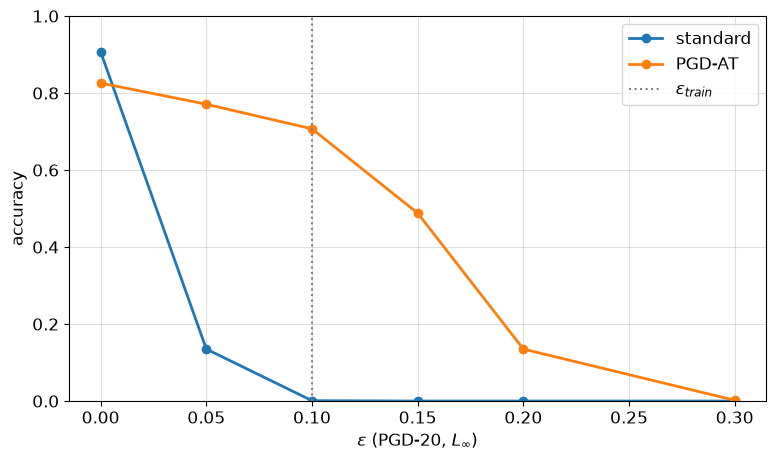

In [62]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Clean accuracy обычной модели равна 90.7%, у PGD-AT она равна 82.6%. Потеря clean accuracy составила 8.1 процентного пункта. За пределами обучающего радиуса 0.1 у PGD-AT получены eps=0.15: 0.488, eps=0.2: 0.135, eps=0.3: 0.002. Защита в меньшем шаре не гарантирует защиту в большем. На один батч PGD-7 AT требует семь проходов для построения атаки и ещё один для обновления весов. Вместо одной пары forward/backward получается примерно восемь. Измеренное время обучения с оценками по эпохам выросло в 4.12 раза.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [63]:
def sanity_checks(model, x, y, eps):
    model.eval()
    totals = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)
    for start in range(0, len(x), 128):
        xb, yb = x[start:start+128], y[start:start+128]
        with torch.no_grad():
            clean_correct = model(xb).argmax(1) == yb

        def still_correct(adv):
            with torch.no_grad():
                return clean_correct & (model(adv).argmax(1) == yb)

        totals['fgsm'] += still_correct(fgsm_attack(model, xb, yb, eps)).sum().item()
        totals['pgd20'] += still_correct(pgd(model, xb, yb, eps, steps=20)).sum().item()
        survives = clean_correct.clone()
        for _ in range(5):
            adv = pgd(model, xb, yb, eps, steps=100)
            survives &= still_correct(adv)
        totals['pgd100_x5'] += survives.sum().item()
        totals['eps_1'] += still_correct(pgd(model, xb, yb, 1.0, steps=20)).sum().item()
    return {key: count/len(x) for key, count in totals.items()}

In [64]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.066      0.004      0.004      0.000
PGD-AT                      0.723      0.711      0.699      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** У standard на 256 объектах FGSM accuracy равна 0.066, PGD-20 равна 0.004, PGD-100 x 5 равна 0.004, а при eps=1 остаётся 0.000. У PGD-AT на 256 объектах FGSM accuracy равна 0.723, PGD-20 равна 0.711, PGD-100 x 5 равна 0.699, а при eps=1 остаётся 0.000. Усиленная атака не повысила accuracy относительно PGD-20. Подозрительного роста оценки устойчивости при усилении атаки здесь нет. Если усиленная атака почти не меняет оценку, это хороший знак для проверки, но ещё не гарантия устойчивости. Стоит дополнительно проверить размер шага, другие loss и объединить найденные ошибки разных атак. Модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти эти sanity checks. В таком случае FGSM просто даёт слишком слабую оценку, а PGD уже показывает отсутствие устойчивости. Согласие проверок само по себе не исключает gradient masking и не даёт сертификата.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [65]:
def input_gradient(model, x, y):
    model.eval()
    gradients = []

    for i in range(len(x)):
        xi = x[i:i+1].detach().clone().requires_grad_(True)
        with torch.enable_grad():
            true_logit = model(xi)[0, y[i]]
            grad, = torch.autograd.grad(true_logit, xi)
        gradients.append(grad.abs().detach())
    return torch.cat(gradients) if gradients else torch.empty_like(x)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()


In [66]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5813173055648804, 'PGD-AT': 0.23080198466777802}

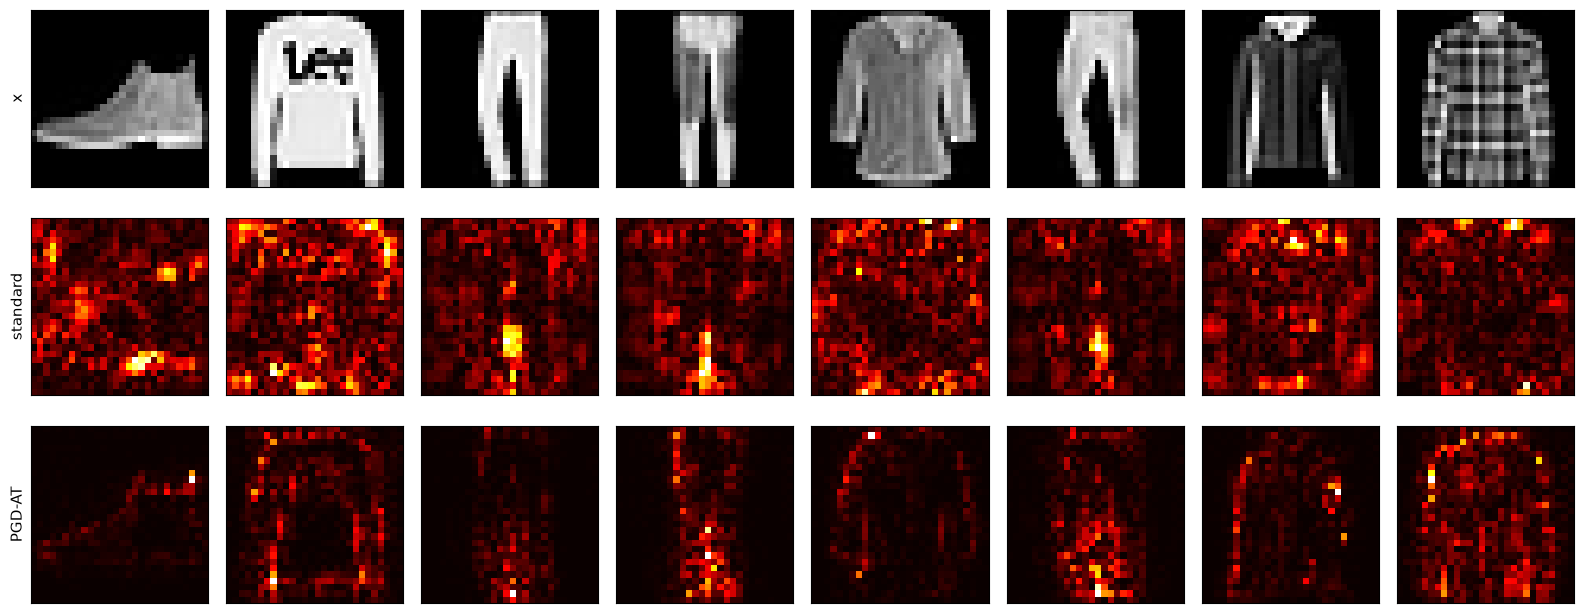

In [67]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** Доля массы |$\nabla_x z_y$| на фоне x=0 равна 0.581 у обычной модели и 0.231 у PGD-AT. На картах обычной модели больше зернистой активности на фоне. У PGD-AT лучше выделяются области и края самих предметов. Каждая карта имеет свою цветовую шкалу. PGD-20 accuracy при eps=0.1 равна 0.001 и 0.707. Это согласуется с различием моделей, но красивой карты недостаточно, чтобы доказать устойчивость. Здесь мы дифференцируем логит истинного класса, а атака использует градиент cross-entropy, то есть рассматривает другую величину.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [68]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['bonus_contract_checks.log', 'BONUS_REPORT.md', 'bonuses', 'clean_run_preparation.json', 'contract_checks.log', 'cuda_saliency_check.json', 'fashion_pgd_at.pt', 'fashion_standard.pt', 'full_run.log', 'gpu_environment.json', 'gpu_installation.log', 'metrics.json', 'notebook.lock', 'resnet20.pt', 'run_code_manifest.json', 'run_full_status.json', 'run_status.json', 'runs', 'sections_2_4', 'training_history.csv', 'TRAINING_LOG.md', 'validation.json', 'visual_observations.json']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [69]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        params, grads, v = list(params), list(grads), list(v)
        if not (len(params) == len(grads) == len(v)):
            raise ValueError('grads, params and v must have equal lengths')
        active = [(g, direction) for g, direction in zip(grads, v)
                  if g is not None and g.requires_grad]
        if not active:
            return tuple(torch.zeros_like(p) for p in params)
        products = torch.autograd.grad(
            [g for g, _ in active], params,
            grad_outputs=[direction for _, direction in active],
            retain_graph=True, allow_unused=True)
        return tuple(torch.zeros_like(p) if h is None else h
                     for p, h in zip(params, products))


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [70]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [71]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

EOS eta=0.05, step=0/3000: loss=0.497282, lambda=4.439, lambda/(2/eta)=0.111


EOS eta=0.05, step=50/3000: loss=0.262078, lambda=5.285, lambda/(2/eta)=0.132


EOS eta=0.05, step=100/3000: loss=0.228245, lambda=6.318, lambda/(2/eta)=0.158


EOS eta=0.05, step=150/3000: loss=0.212675, lambda=6.917, lambda/(2/eta)=0.173


EOS eta=0.05, step=200/3000: loss=0.202599, lambda=7.346, lambda/(2/eta)=0.184


...

EOS eta=0.2, step=2800/3000: loss=0.067972, lambda=11.011, lambda/(2/eta)=1.101


EOS eta=0.2, step=2850/3000: loss=0.067996, lambda=10.889, lambda/(2/eta)=1.089


EOS eta=0.2, step=2900/3000: loss=0.072563, lambda=11.073, lambda/(2/eta)=1.107


EOS eta=0.2, step=2950/3000: loss=0.066688, lambda=10.869, lambda/(2/eta)=1.087


EOS eta=0.2, step=3000/3000: loss=0.068161, lambda=10.885, lambda/(2/eta)=1.088


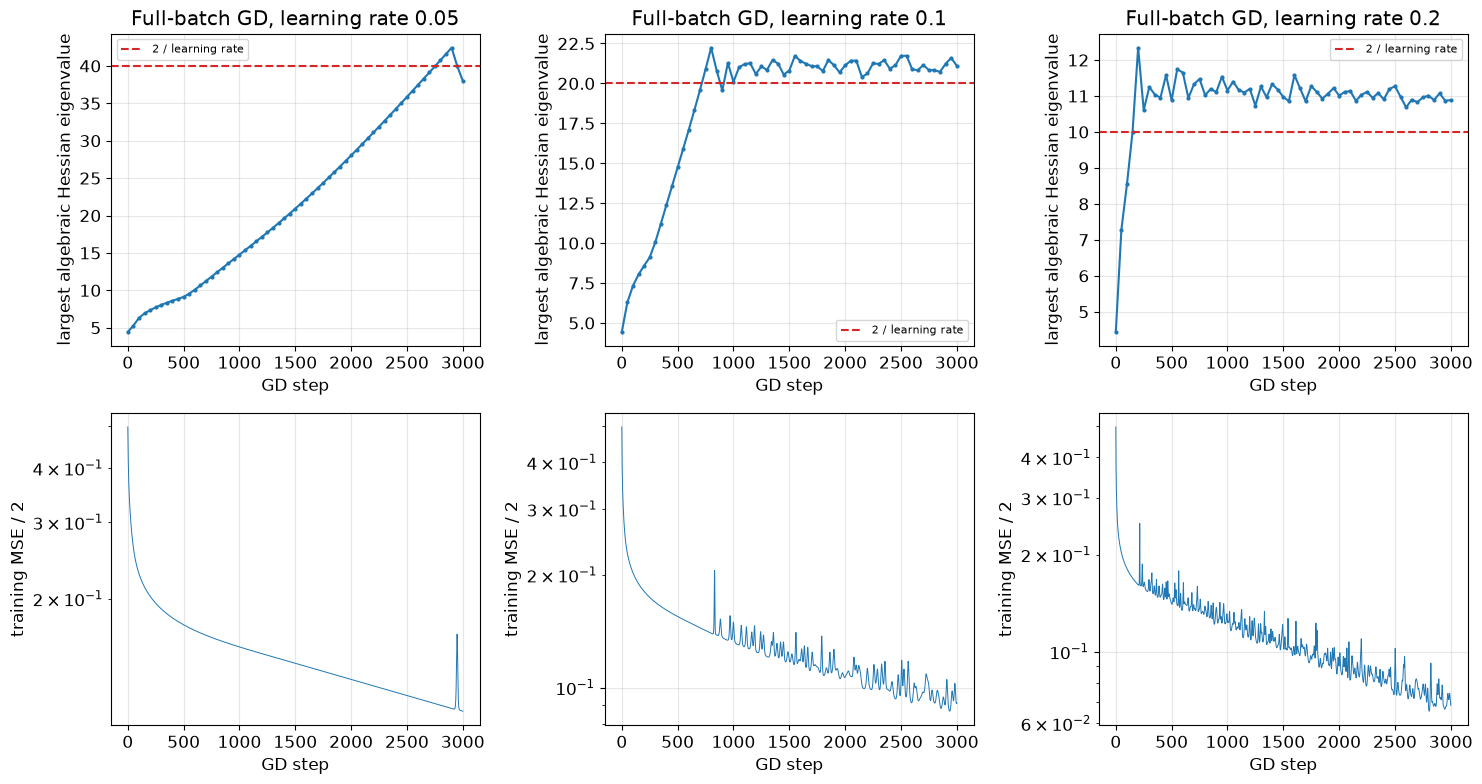

In [72]:
if '7.1' in BONUS_TASKS:
    EOS_LRS = [0.05, 0.1, 0.2]  # фиксируем до запуска, не подгоняем под форму графика
    EOS_EVERY = 50
    EOS_LANCZOS_ITERS = 20
    eos_results = {}
    for eta in EOS_LRS:
        set_seed(0)
        eos_model = make_tanh_mlp(seed=0)
        eos_optimizer = torch.optim.SGD(eos_model.parameters(), lr=eta)
        result = dict(lr=eta, threshold=2/eta, loss=[], sharpness_steps=[],
                      sharpness=[], status='complete')
        warm_vector = None
        started = time.perf_counter()
        for step in range(EOS_STEPS+1):
            eos_optimizer.zero_grad(set_to_none=True)
            loss = mse_loss(eos_model)
            value = loss.item()
            if not math.isfinite(value):
                result['status'] = 'nonfinite_loss'
                result['stopped_at'] = step
                result['loss'].append(None)
                break
            result['loss'].append(value)
            if step % EOS_EVERY == 0:
                lam, warm_vector = top_eigenvalue(
                    lambda: mse_loss(eos_model), eos_model.parameters(),
                    iters=EOS_LANCZOS_ITERS, v=warm_vector)
                result['sharpness_steps'].append(step)
                result['sharpness'].append(lam)
                print(f'EOS eta={eta:g}, step={step}/{EOS_STEPS}: '
                      f'loss={value:.6f}, lambda={lam:.3f}, '
                      f'lambda/(2/eta)={lam*eta/2:.3f}', flush=True)
            if step < EOS_STEPS:
                loss.backward()
                eos_optimizer.step()
        result['seconds'] = time.perf_counter()-started
        eos_results[str(eta)] = result
    RUN_TIMES['bonus_eos_seconds'] = sum(r['seconds'] for r in eos_results.values())
    fig, axes = plt.subplots(2, len(EOS_LRS), figsize=(15, 8))
    for column, eta in enumerate(EOS_LRS):
        result = eos_results[str(eta)]
        axes[0,column].plot(result['sharpness_steps'], result['sharpness'], 'o-', markersize=2)
        axes[0,column].axhline(2/eta, color='tab:red', linestyle='--', label='2 / learning rate')
        axes[0,column].set_title(f'Full-batch GD, learning rate {eta:g}')
        axes[0,column].set_ylabel('largest algebraic Hessian eigenvalue')
        axes[0,column].legend(fontsize=8)
        axes[1,column].semilogy(range(len(result['loss'])),
            [float('nan') if v is None else v for v in result['loss']], linewidth=0.7)
        axes[1,column].set_ylabel('training MSE / 2')
        for ax in axes[:,column]:
            ax.set_xlabel('GD step')
            ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** При η=0.05 первое приближение к 2/η с допуском 10% на шаге 2550. Финальное отношение λ/(2/η) равно 0.95, а loss изменился с 0.4973 до 0.1101. При η=0.1 первое приближение к 2/η с допуском 10% на шаге 650. Финальное отношение λ/(2/η) равно 1.06, а loss изменился с 0.4973 до 0.0909. При η=0.2 первое приближение к 2/η с допуском 10% на шаге 150. Финальное отношение λ/(2/η) равно 1.09, а loss изменился с 0.4973 до 0.0682. После приближения к границе loss может колебаться, продолжая снижаться в целом. При меньшем lr выход к границе происходит позже. В квадратичной задаче гессиан постоянен, а у нейросети он меняется во время обучения и может иметь отрицательные собственные числа. Поэтому локальный критерий не гарантирует такую же динамику всей сети. Lanczos даёт оценку наибольшего собственного числа. Замеры раз в 50 шагов могут пропускать короткие всплески.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [73]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        B, C_in, H, W = x.shape
        C_out, C_group, kh, kw = weight.shape
        if (groups < 1 or C_in % groups or C_out % groups
                or C_group != C_in//groups or stride < 1 or padding < 0):
            raise ValueError('Invalid convolution configuration')
        padded = F.pad(x, (padding, padding, padding, padding))
        hp, wp = padded.shape[-2:]
        if hp < kh or wp < kw:
            raise ValueError('Kernel is larger than the padded input')
        fft_shape = (hp+kh-1, wp+kw-1)
        x_freq = torch.fft.rfft2(padded, s=fft_shape)
        w_freq = torch.fft.rfft2(weight.flip((-2,-1)), s=fft_shape)
        fh, fw = x_freq.shape[-2:]
        x_freq = x_freq.reshape(B, groups, C_group, fh, fw)
        w_freq = w_freq.reshape(groups, C_out//groups, C_group, fh, fw)
        product = torch.einsum('bgihw,goihw->bgohw', x_freq, w_freq)
        full = torch.fft.irfft2(product, s=fft_shape).reshape(B,C_out,*fft_shape)
        out = full[..., kh-1:hp:stride, kw-1:wp:stride]
        return out if bias is None else out+bias.view(1,-1,1,1)

In [74]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** Если valid-область имеет размер H x W, stride s оставляет ceil(H/s)\*ceil(W/s) значений из H\*W. Значит, доля отброшенных равна 1−ceil(H/s)\*ceil(W/s)/(H·W), примерно 1−1/s^2. При s=2 это около 75%, при s=3 около 89%. Если считать всю плоскость IFFT, дополнительно отбрасываются края. FFT может окупиться для больших ядер и карт, особенно если преобразования можно использовать повторно. Для маленьких ядер или большого stride лишние вычисления и память часто мешают. Все 81 конфигурация совпали с conv2d, но сравнение скорости здесь не проводилось.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [75]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        if M.ndim != 2:
            raise ValueError('Expected a matrix')
        # FP32 (или FP64 для double) сохраняет точность; reference использует BF16.
        X = M.double() if M.dtype == torch.float64 else M.float()
        transposed = X.shape[0] > X.shape[1]
        if transposed:
            X = X.T
        X = X/X.norm().clamp_min(1e-7)
        a,b,c = coeffs
        for _ in range(steps):
            gram = X@X.T
            X = a*X+(b*gram+c*(gram@gram))@X
        return (X.T if transposed else X).to(M.dtype)


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))
            if any(p.ndim < 2 for g in self.param_groups for p in g['params']):
                raise ValueError('ConvMuon requires parameters with at least two dimensions')

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    if p.grad.is_sparse:
                        raise RuntimeError('Sparse gradients are not supported')
                    state = self.state[p]
                    if not state:
                        state['momentum_buffer'] = torch.zeros_like(p)
                    buffer = state['momentum_buffer']
                    buffer.mul_(mu).add_(p.grad, alpha=1-mu)
                    update = (1-mu)*p.grad+mu*buffer
                    rows = p.shape[0]
                    columns = p.numel()//rows
                    direction = newton_schulz(update.reshape(rows,columns)).reshape_as(p)
                    p.add_(direction, alpha=-group['lr']*math.sqrt(max(1,rows/columns)))

In [76]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [77]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    set_seed(0)
    model_muon = ResNetCIFAR(20).to(device)
    conv_params = [p for p in model_muon.parameters() if p.ndim==4]
    other = [p for p in model_muon.parameters() if p.ndim!=4]
    muon_optimizer = ConvMuon(conv_params, lr=MUON_LR)
    adam_optimizer = MyAdamW([
        dict(params=[p for p in other if p.ndim>1], weight_decay=0.05),
        dict(params=[p for p in other if p.ndim<=1], weight_decay=0.0)], lr=LR)
    muon_steps_total = EPOCHS*math.ceil(len(X_train)/256)
    muon_schedulers = [torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: cosine_lr(step,muon_steps_total))
        for optimizer in [muon_optimizer,adam_optimizer]]
    hist_muon = dict(train_loss=[],test_acc=[])
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        model_muon.train()
        loss_sum = 0.0
        order = torch.randperm(len(X_train),device=X_train.device)
        for cursor,start in enumerate(range(0,len(X_train),256),1):
            idx = order[start:start+256]
            xb,yb = normalize(X_train[idx]),Y_train[idx]
            muon_optimizer.zero_grad(set_to_none=True)
            adam_optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model_muon(xb),yb)
            loss.backward()
            muon_optimizer.step()
            adam_optimizer.step()
            for scheduler in muon_schedulers:
                scheduler.step()
            loss_sum += loss.item()*len(yb)
        hist_muon['train_loss'].append(loss_sum/len(X_train))
        hist_muon['test_acc'].append(accuracy(predict_logits(model_muon,X_test,
            batch_size=256,transform=normalize),Y_test))
        print(f'Muon epoch {epoch+1}/{EPOCHS}: loss={hist_muon["train_loss"][-1]:.4f}, '
              f'test_acc={hist_muon["test_acc"][-1]:.4f}',flush=True)
    RUN_TIMES['bonus_muon_seconds'] = time.perf_counter()-started
    muon_state_bytes = sum(v.numel()*v.element_size() for state in muon_optimizer.state.values()
                           for v in state.values() if isinstance(v,torch.Tensor))
    muon_adam_state_bytes = sum(v.numel()*v.element_size() for state in adam_optimizer.state.values()
                                for v in state.values() if isinstance(v,torch.Tensor))
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')


Muon epoch 1/20: loss=1.1442, test_acc=0.6294


Muon epoch 2/20: loss=0.6695, test_acc=0.7527


Muon epoch 3/20: loss=0.5083, test_acc=0.7805


Muon epoch 4/20: loss=0.4000, test_acc=0.7979


Muon epoch 5/20: loss=0.3191, test_acc=0.8097


...

Muon epoch 17/20: loss=0.0020, test_acc=0.8553


Muon epoch 18/20: loss=0.0012, test_acc=0.8555


Muon epoch 19/20: loss=0.0009, test_acc=0.8563


Muon epoch 20/20: loss=0.0008, test_acc=0.8565


            train loss  test acc
AdamW           0.0140    0.8296
Muon            0.0008    0.8565


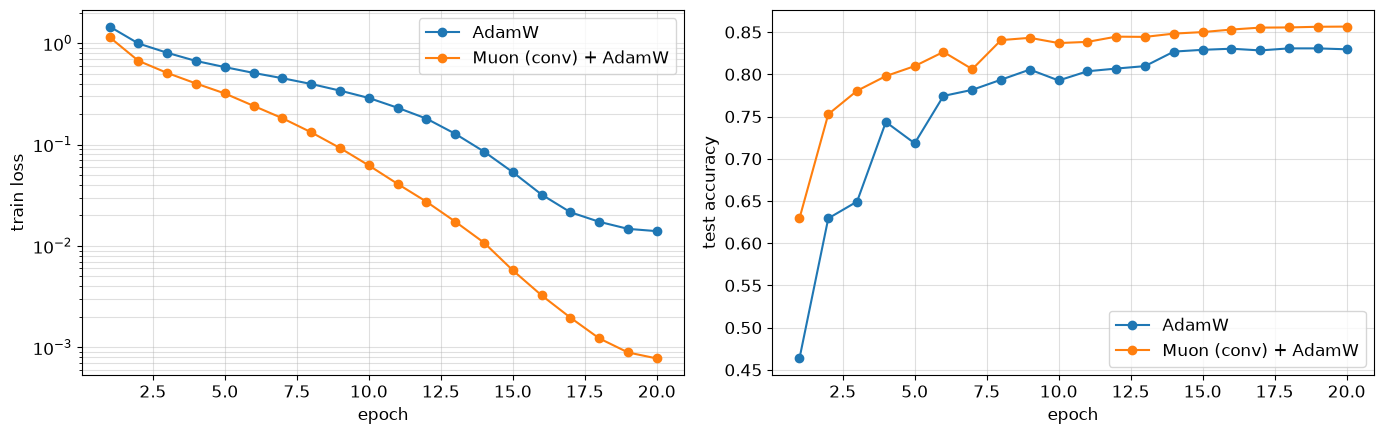

In [78]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** К пятой эпохе train loss равен 0.5806 у AdamW и 0.3191 у Muon. К этой точке быстрее снижал loss вариант с Muon. В конце 20 эпох loss равен 0.0140 и 0.0008, test accuracy равна 82.96% и 85.65%. Лучший итоговый test результат дал вариант с Muon. Но это один seed и два разных набора lr и weight decay, поэтому общего вывода о превосходстве оптимизатора сделать нельзя. Для FP32 Muon хранит один momentum tensor, то есть 4 байта на параметр. AdamW хранит два момента, то есть 8 байт, плюс служебные счётчики. В нашем смешанном варианте состояние Muon занимает 1,081,024 байт, а AdamW для остальных параметров занимает 17,744 байт. Временные матрицы Newton–Schulz сюда не входят.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [79]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [80]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.91, 'L0, k=5': 0.554}


standard    0.910  0.866  0.804  0.732  0.554  0.368  0.168  0.044
PGD-AT      0.840  0.812  0.782  0.762  0.720  0.630  0.420  0.310


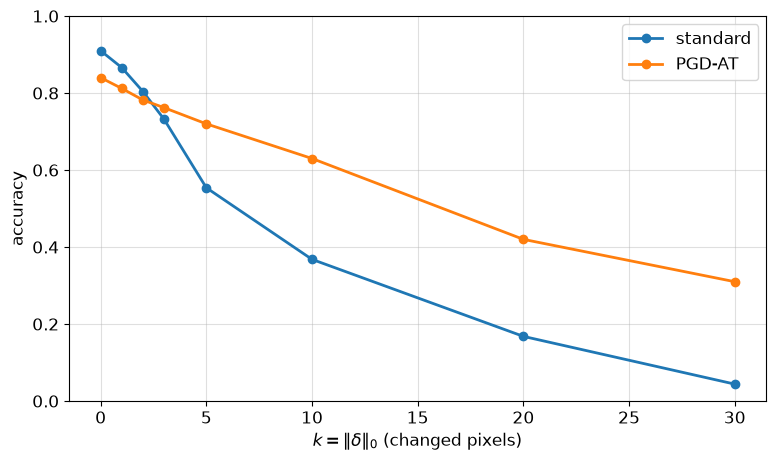

In [81]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** В этом опыте L_inf-робастность помогла. На 500 изображениях clean accuracy равна 0.910 у standard и 0.840 у PGD-AT. При k=5 она равна 0.554 и 0.720, при k=30 равна 0.044 и 0.310. Падение относительно своего clean результата составляет 0.866 и 0.530. Это наблюдение о переносе устойчивости, а не гарантия защиты от L0. Изменение одного пикселя с 0 до 1 имеет L_inf-норму 1 и выходит за обучающий радиус 0.1. Поэтому такая атака не обязана быть безопасной для L_inf-робастной модели.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [82]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM


Fashion fgsm_attack-eps-0.2, epoch 1/5: loss=1.1918, clean=0.700, FGSM=0.620, PGD-20=0.037, minutes=0.1


Fashion fgsm_attack-eps-0.2, epoch 2/5: loss=0.6548, clean=0.531, FGSM=0.915, PGD-20=0.001, minutes=0.1


Fashion fgsm_attack-eps-0.2, epoch 3/5: loss=0.1913, clean=0.440, FGSM=0.970, PGD-20=0.000, minutes=0.2


Fashion fgsm_attack-eps-0.2, epoch 4/5: loss=0.1090, clean=0.448, FGSM=0.978, PGD-20=0.001, minutes=0.2


...

Fashion fgsm_rs_attack-eps-0.2, epoch 1/5: loss=1.1903, clean=0.780, FGSM=0.601, PGD-20=0.324, minutes=0.1


Fashion fgsm_rs_attack-eps-0.2, epoch 2/5: loss=0.8998, clean=0.789, FGSM=0.658, PGD-20=0.389, minutes=0.1


Fashion fgsm_rs_attack-eps-0.2, epoch 3/5: loss=0.7822, clean=0.793, FGSM=0.697, PGD-20=0.411, minutes=0.2


Fashion fgsm_rs_attack-eps-0.2, epoch 4/5: loss=0.7175, clean=0.808, FGSM=0.716, PGD-20=0.389, minutes=0.2


Fashion fgsm_rs_attack-eps-0.2, epoch 5/5: loss=0.6678, clean=0.799, FGSM=0.739, PGD-20=0.376, minutes=0.3


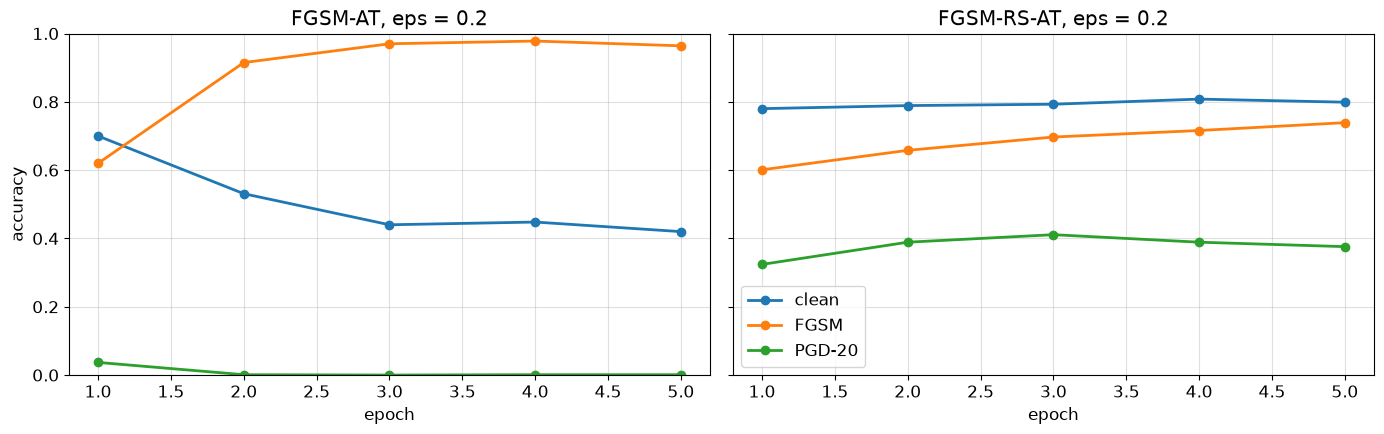

In [83]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [84]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.41015625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.7265625, 'pgd20': 0.37109375, 'pgd100_x5': 0.328125, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** У FGSM PGD-20 accuracy по эпохам: 0.037, 0.001, 0.000, 0.001, 0.001. Наибольшее снижение между соседними эпохами составило 3.6 п.п. к эпохе 2. Финальная FGSM accuracy равна 0.964. У FGSM-RS PGD-20 accuracy по эпохам: 0.324, 0.389, 0.411, 0.389, 0.376. Наибольшее снижение между соседними эпохами составило 2.2 п.п. к эпохе 4. Финальная FGSM accuracy равна 0.739. У FGSM-AT видна картина, согласующаяся с catastrophic overfitting: высокая FGSM accuracy сочетается с почти нулевой PGD accuracy. После первой эпохи PGD accuracy уже мала, поэтому точный момент возможного обвала внутри этой эпохи неизвестен. Random start изменил итоговую PGD-20 accuracy на +0.375. Резкого позднего снижения PGD accuracy у random start в этом бюджете не видно. Усиленная PGD-100x5 на 256 объектах оставила accuracy 0.000 и 0.328.

Готовые кривые считают accuracy на атакованных изображениях. Атака иногда исправляет clean-ошибку, поэтому FGSM-кривая может оказаться выше clean. В sanity_checks учитываются и clean-ошибки. Там FGSM accuracy модели FGSM-AT равна 0.410. С кривой на 1000 объектах различаются и определение, и выборка.

Проверяемая гипотеза: начало деградации зависит от шага внешнего Adam. Для отдельного опыта можно заранее сравнить lr=0.001 и 0.0003 при тех же eps=0.2 и пяти эпохах, взять несколько seed и чаще измерять PGD accuracy. Настройки стоит выбирать по validation